# Additive Transcription
I'm interested if the combination of experiencing hypoxia and warming together results in additive transcription (the effect of experiencing both is the sum of experiencing the single stressors).

Following a pipeline from [Jordine et al 2026](https://link-springer-com.umasslowell.idm.oclc.org/content/pdf/10.1186/s12870-026-08595-7.pdf) - they looked at hypoxia and salt stress in plants.

## 0. load libraries

In [2]:
library(tidyverse)

## 1. read CSVs
The paper used only pairwise comparisons that used control conditions as the reference - so here, I want to pull out B vs. C, H vs. C, and W vs. C comparisons

### deseq results

In [21]:
bc <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase1_v_phase1/deseq_res/prefilter_deseq/p1.both_v_cont.csv')
hc <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase1_v_phase1/deseq_res/prefilter_deseq/p1.hyp_v_cont.csv')
wc <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase1_v_phase1/deseq_res/prefilter_deseq/p1.warm_v_cont.csv')
head(bc)

,X,baseMean,log2FoldChange,lfcSE,pvalue,padj
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,LOC144621260,2772.7662,0.0006760298,0.02228152,7.787130e-01,0.996753837
2,LOC144621269,6797.3814,0.0043068296,0.10994540,5.813767e-01,0.992028790
3,LOC111120925,191.4430,-4.8969080894,1.40934377,8.354541e-06,0.003582926
4,LOC144621283,932.0540,0.0011781837,0.02371160,6.197830e-01,0.992275338
5,LOC144621276,12350.8892,0.0012266259,0.02481032,5.976185e-01,0.992028790
6,LOC111115920,213.3386,0.0676056817,0.25031860,6.160028e-03,0.234877458


### vst

In [17]:
vst <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase1_v_phase1/deseq_res/prefilter_deseq/p1_vst.csv') %>%
rename('Gene' = X) %>%
pivot_longer(col = -Gene,
            names_to = 'Sample',
            values_to = 'vst_expr')

head(vst)

Gene,Sample,vst_expr
<chr>,<chr>,<dbl>
LOC144621260,B1_Nu_O03,11.21797
LOC144621260,B2_Nu_O12,11.93477
LOC144621260,B4_Nu_O32,11.22476
LOC144621260,B5_Nu_O36,11.38600
LOC144621260,B6_Nu_O47,11.49149
LOC144621260,C1_Nu_W01,11.33041


### metadata

In [33]:
meta <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/metaData/sample_metaData.csv')
head(meta)

,Sample,Phase1_treatment,Phase1_temp,Phase1_DO,Phase1_TankRep,Phase2_treatment,Phase2_temp,Phase2_DO,Phase2_TankRep
,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<int>
1,B1_B1_O01,both,warm,hypoxic,1,both,warm,hypoxic,1
2,B1_Nu_O03,both,warm,hypoxic,1,NA,NA,NA,NA
3,B1_W5_O50,both,warm,hypoxic,1,warm,warm,normoxic,5
4,B2_B5_O51,both,warm,hypoxic,2,both,warm,hypoxic,5
5,B2_C4_O40,both,warm,hypoxic,2,control,ambient,normoxic,4
6,B2_Nu_O12,both,warm,hypoxic,2,NA,NA,NA,NA


## 2. identify B vs. C DEGs
get list of significantly differentially expressed genes from the both vs. control comparison

In [23]:
bc.deg <- bc %>%
filter(padj < 0.05 & abs(log2FoldChange) > 1) %>%
select(X, lfc_both = log2FoldChange)


dim(bc.deg) # 255 DEGs
head(bc.deg)

[1] 216   2

,X,lfc_both
,<chr>,<dbl>
1,LOC111120925,-4.896908
2,LOC111103173,4.218534
3,LOC111105159,-5.231786
4,LOC111132252,-2.652227
5,LOC111137262,3.700067
6,LOC111105069,-3.773655


### pull B vs. C DEGs from other comparisons

In [24]:
# WARM vs. CONTROL
wc.genes <- wc %>%
filter(X %in% bc.deg$X) %>%
select(X, log2FoldChange, padj) 

dim(wc.genes)

# HYPOXIC vs. CONTROL
hc.genes <- hc %>%
filter(X %in% bc.deg$X) %>%
select(X, log2FoldChange, padj)

dim(hc.genes)
head(hc.genes)

[1] 216   3

[1] 216   3

,X,log2FoldChange,padj
,<chr>,<dbl>,<dbl>
1,LOC111120925,-0.0067857372,0.9279668
2,LOC111103173,0.0047568860,0.9650128
3,LOC111105159,-0.1176474534,0.4983497
4,LOC111132252,0.0025764414,0.9784646
5,LOC111137262,1.1565411385,0.1060058
6,LOC111105069,0.0009826917,0.9900027


In [25]:
merged <- wc.genes %>%
  select(X, lfc_warm = log2FoldChange) %>%
  inner_join(
    hc.genes %>%
      select(X, lfc_hypoxia = log2FoldChange),
    by = "X"
  ) %>%
  mutate(expected_lfc = lfc_warm + lfc_hypoxia)

head(merged)

,X,lfc_warm,lfc_hypoxia,expected_lfc
,<chr>,<dbl>,<dbl>,<dbl>
1,LOC111120925,-0.15664820,-0.0067857372,-0.163433933
2,LOC111103173,0.02156670,0.0047568860,0.026323582
3,LOC111105159,-3.97024338,-0.1176474534,-4.087890835
4,LOC111132252,-0.00486462,0.0025764414,-0.002288178
5,LOC111137262,2.60145813,1.1565411385,3.757999272
6,LOC111105069,-0.03271385,0.0009826917,-0.031731158


In [26]:
merged.df <- merge(bc.deg, merged, by = 'X')

dim(merged.df)
head(merged.df)

[1] 216   5

,X,lfc_both,lfc_warm,lfc_hypoxia,expected_lfc
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,LOC111099801,-7.473097,0.003157232,-1.474121e-06,0.003155758
2,LOC111099828,-6.319057,-0.010545524,-2.428386e-03,-0.012973910
3,LOC111099841,-6.748610,-0.027575194,2.645875e-04,-0.027310607
4,LOC111099910,-4.676149,-0.103918549,-1.838041e-03,-0.105756590
5,LOC111099974,-8.125159,-0.103102606,-5.551361e-03,-0.108653967
6,LOC111100030,-22.183811,-0.005973193,8.411853e-04,-0.005132008


## 3. plot both vs. sum(single)

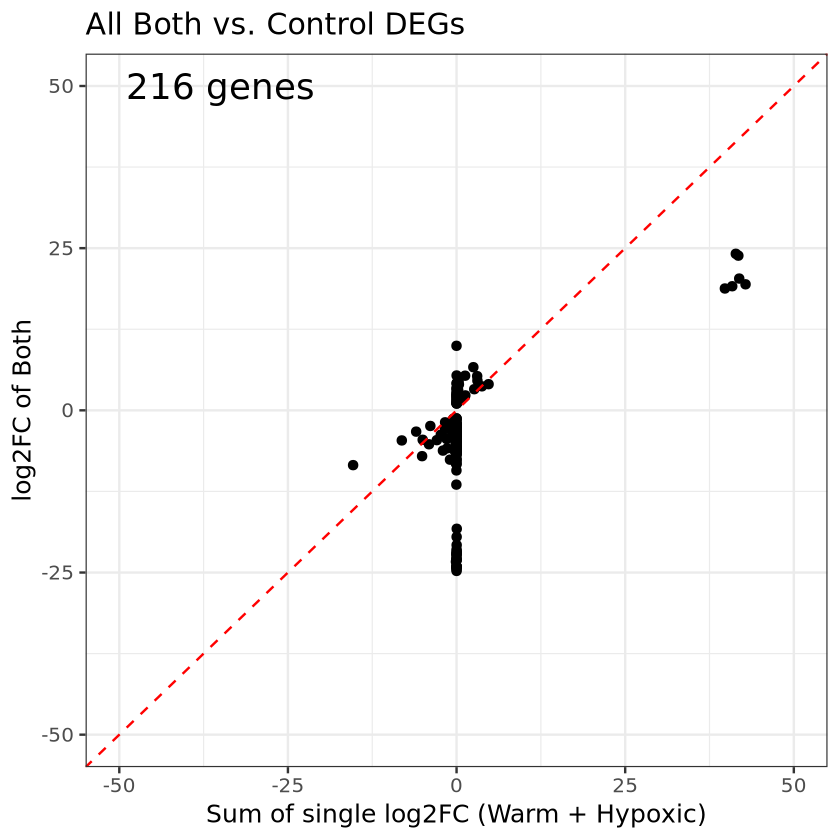

In [27]:
ggplot(merged.df, aes(x = expected_lfc, y = lfc_both)) +
geom_point() +

# add 1:1 line
geom_abline(slope = 1, intercept = 0, color = "red", linetype = "dashed") +

# keep axes the same
ylim(-50,50) +
xlim(-50,50) +

# add text to plot
annotate("text", x = -35, y = 50, label = "216 genes", color = "black", size = 7.5) +

# theme and labels
labs(x = 'Sum of single log2FC (Warm + Hypoxic)',
    y = 'log2FC of Both',
    title = 'All Both vs. Control DEGs') +
theme_bw(base_size = 15)

**observations**:
- some of the genes that had no expression changes for single stressor vs. control had very large changes when both stressors are experienced simultaneously (all the points on the 0 x-axis line)
- points below the 1:1 line - the sum of the single stressors was larger than the expression change of both stressors - **divergent or antagonistic expression**
- points above the 1:1 line - the sum of the single stressors was less than the expression change of both stressors - **enhanced or synergistic expression**
- points on the 1:1 line - the sum is the same as the combined effect - **additive expression**

would have to go back and statistically assign additive/divergent/enhanced 

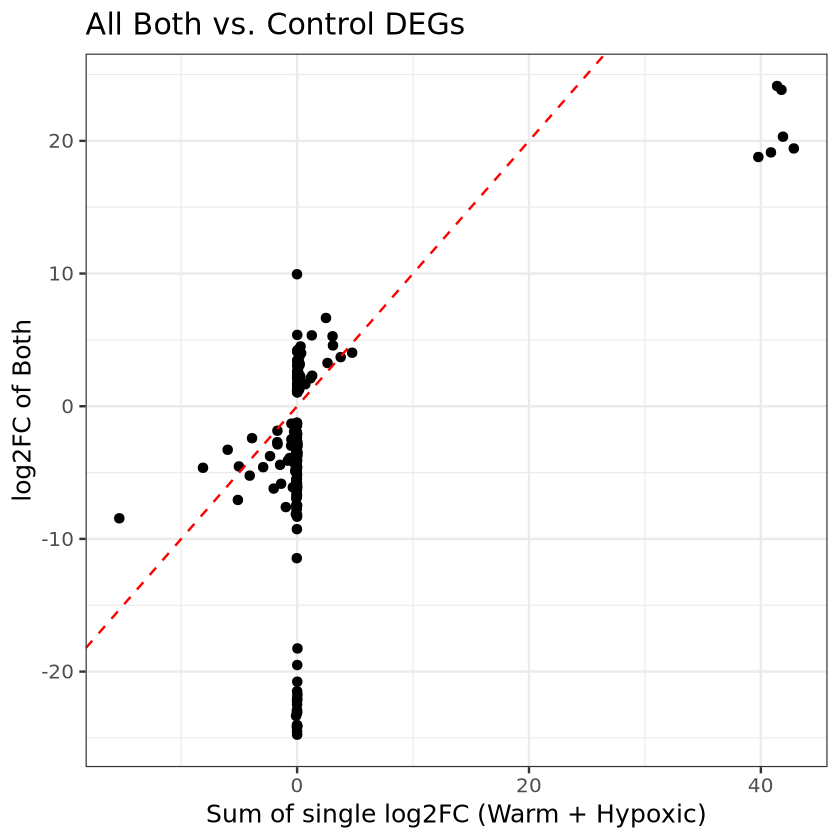

In [28]:
ggplot(merged.df, aes(x = expected_lfc, y = lfc_both)) +
geom_point() +

# add 1:1 line
geom_abline(slope = 1, intercept = 0, color = "red", linetype = "dashed") +

# keep axes the same
#ylim(-30,30) +
#xlim(-30,50) +

# add text to plot
#annotate("text", x = -35, y = 50, label = "235 genes", color = "black", size = 7.5) +

# theme and labels
labs(x = 'Sum of single log2FC (Warm + Hypoxic)',
    y = 'log2FC of Both',
    title = 'All Both vs. Control DEGs') +
theme_bw(base_size = 15)

## 4. plot vst 

In [32]:
bc.deg.vst <- vst[vst$Gene %in% merged.df$X,]
head(bc.deg.vst)

Gene,Sample,vst_expr
<chr>,<chr>,<dbl>
LOC111120925,B1_Nu_O03,6.162650
LOC111120925,B2_Nu_O12,6.596958
LOC111120925,B4_Nu_O32,6.709412
LOC111120925,B5_Nu_O36,6.097391
LOC111120925,B6_Nu_O47,6.365111
LOC111120925,C1_Nu_W01,6.642652


In [35]:
deg.df <- merge(bc.deg.vst, meta, by = 'Sample')
head(deg.df)

,Sample,Gene,vst_expr,Phase1_treatment,Phase1_temp,Phase1_DO,Phase1_TankRep,Phase2_treatment,Phase2_temp,Phase2_DO,Phase2_TankRep
,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<int>
1,B1_Nu_O03,LOC111120925,6.162650,both,warm,hypoxic,1,NA,NA,NA,NA
2,B1_Nu_O03,LOC111137079,8.333535,both,warm,hypoxic,1,NA,NA,NA,NA
3,B1_Nu_O03,LOC144621605,5.984862,both,warm,hypoxic,1,NA,NA,NA,NA
4,B1_Nu_O03,LOC144625776,7.670560,both,warm,hypoxic,1,NA,NA,NA,NA
5,B1_Nu_O03,LOC111101829,6.840602,both,warm,hypoxic,1,NA,NA,NA,NA
6,B1_Nu_O03,LOC111124622,5.806396,both,warm,hypoxic,1,NA,NA,NA,NA


In [55]:
# HYPOXIC
hyp.vst <- deg.df %>% 
filter(Phase1_treatment == 'hypoxic') %>% 
select('Sample', 'Gene', 'vst_expr', 'Phase1_treatment') %>% 
group_by(Gene) %>% 
summarise(mean_vst = mean(vst_expr))

# WARM
warm.vst <- deg.df %>% 
filter(Phase1_treatment == 'warm') %>% 
select('Sample', 'Gene', 'vst_expr', 'Phase1_treatment') %>% 
group_by(Gene) %>% 
summarise(mean_vst = mean(vst_expr))

head(warm.vst)

Gene,mean_vst
<chr>,<dbl>
LOC111099801,9.928493
LOC111099828,6.603457
LOC111099841,7.081047
LOC111099910,7.396147
LOC111099974,6.331563
LOC111100030,6.144756


In [58]:
vst_expected <- merge(hyp.vst, warm.vst, by = 'Gene') %>%
mutate(expected_vst = mean_vst.x + mean_vst.y) %>% 
select(Gene, expected_vst)

head(vst_expected)

,Gene,expected_vst
,<chr>,<dbl>
1,LOC111099801,18.95970
2,LOC111099828,13.52260
3,LOC111099841,15.10794
4,LOC111099910,15.98910
5,LOC111099974,13.25111
6,LOC111100030,13.03050


In [61]:
both.df <- deg.df %>% 
filter(Phase1_treatment == 'both') %>% 
select(Gene, vst_expr) %>%
group_by(Gene) %>%
summarise(mean_vst = mean(vst_expr))

head(both.df)

Gene,mean_vst
<chr>,<dbl>
LOC111099801,6.077306
LOC111099828,5.871617
LOC111099841,6.032165
LOC111099910,6.487803
LOC111099974,5.856295
LOC111100030,5.806396


In [62]:
vst_final <- merge(vst_expected, both.df, by = 'Gene')
head(vst_final)

,Gene,expected_vst,mean_vst
,<chr>,<dbl>,<dbl>
1,LOC111099801,18.95970,6.077306
2,LOC111099828,13.52260,5.871617
3,LOC111099841,15.10794,6.032165
4,LOC111099910,15.98910,6.487803
5,LOC111099974,13.25111,5.856295
6,LOC111100030,13.03050,5.806396


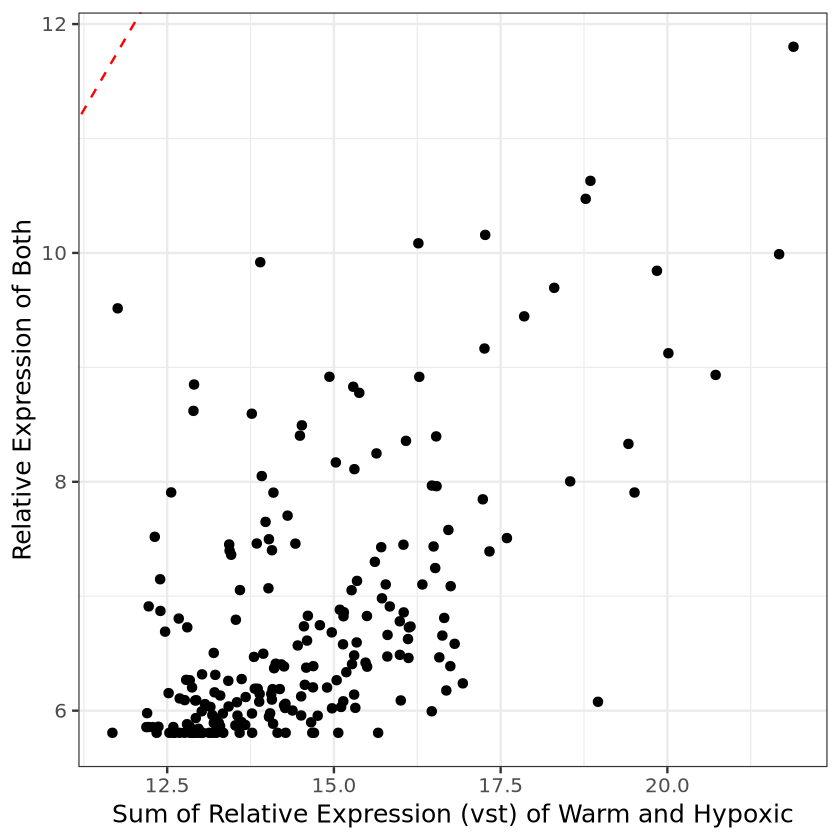

In [66]:
ggplot(vst_final, aes(x = expected_vst, y = mean_vst)) +
geom_point() +
geom_abline(slope = 1, intercept = 0, color = "red", linetype = "dashed") +
labs(x = 'Sum of Relative Expression (vst) of Warm and Hypoxic',
     y = 'Relative Expression of Both') +
theme_bw(base_size = 15)